In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
!pip install -q mlflow dagshub

In [65]:
import pandas as pd
from pathlib import Path

from sklearn.model_selection import train_test_split

import torch
import torchvision
from torchvision import transforms
from torchvision.transforms import functional as TF
from torch.utils.data import Dataset, DataLoader

import torch.nn as nn
from PIL import Image
import matplotlib.pyplot as plt

import mlflow
import mlflow.pytorch

import os
from google.colab import userdata

import time
import copy

import json
import numpy as np
import random

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

from torchvision.models import resnet50, ResNet50_Weights

In [6]:
print(torch.cuda.is_available())

True


In [7]:
# Definition

classes = ["ASCUS", "HSIL", "LSIL", "SCC", "NILM"]

# working_path = Path("../data/processed/cleaned_data")

working_path = Path("/content/drive/MyDrive/Cervical_Cancer_Project/working_dataset")

In [8]:
# Getting the data

data = []

for class_name in classes:

    folder = working_path / class_name

    for image_path in folder.iterdir():

        if image_path.suffix.lower() in ['.jpg', '.png', 'jpeg']:

            data.append({
                "image_path": str(image_path),
                "label": class_name
            })

df = pd.DataFrame(data)

df.head()



,image_path,label
0,/content/drive/MyDrive/Cervical_Cancer_Project...,ASCUS
1,/content/drive/MyDrive/Cervical_Cancer_Project...,ASCUS
2,/content/drive/MyDrive/Cervical_Cancer_Project...,ASCUS
3,/content/drive/MyDrive/Cervical_Cancer_Project...,ASCUS
4,/content/drive/MyDrive/Cervical_Cancer_Project...,ASCUS


In [9]:
print("Total Images: ", len(df))
print(df['label'].value_counts())

Total Images:  5566
label
NILM     1790
HSIL     1442
LSIL     1230
ASCUS     645
SCC       459
Name: count, dtype: int64


In [10]:


df.head(10)

,image_path,label
0,/content/drive/MyDrive/Cervical_Cancer_Project...,ASCUS
1,/content/drive/MyDrive/Cervical_Cancer_Project...,ASCUS
2,/content/drive/MyDrive/Cervical_Cancer_Project...,ASCUS
3,/content/drive/MyDrive/Cervical_Cancer_Project...,ASCUS
4,/content/drive/MyDrive/Cervical_Cancer_Project...,ASCUS
5,/content/drive/MyDrive/Cervical_Cancer_Project...,ASCUS
6,/content/drive/MyDrive/Cervical_Cancer_Project...,ASCUS
7,/content/drive/MyDrive/Cervical_Cancer_Project...,ASCUS
8,/content/drive/MyDrive/Cervical_Cancer_Project...,ASCUS
9,/content/drive/MyDrive/Cervical_Cancer_Project...,ASCUS


In [10]:
# Splitting the data into Train, Val and Test

# Train Vs Test

train_df, temp_df = train_test_split(
    df,
    test_size=0.3,
    stratify=df['label'],
    random_state=42
)

# Test Vs Val

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    stratify=temp_df['label'],
    random_state=42
)

print("Training: ", len(train_df))
print("Validation: ", len(val_df))
print("Testing: ", len(test_df))

Training:  3896
Validation:  835
Testing:  835


In [11]:
# Lets verify Class Distribution

split_distribution = pd.DataFrame({
    "Train": train_df['label'].value_counts(),
    "Val": val_df['label'].value_counts(),
    "Test": test_df['label'].value_counts()
}).fillna(0).astype(int).reset_index()

split_distribution

,label,Train,Val,Test
0,NILM,1253,268,269
1,HSIL,1009,217,216
2,LSIL,861,184,185
3,ASCUS,452,97,96
4,SCC,321,69,69


Image Processing

In [12]:
# Defining the image transformations:

IMG_SIZE = 512

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.0485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE,IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [13]:
# We will now add padding

class ResizeWithPadding:

  def __init__(self, size):
    self.size = size

  def __call__(self, image):
    width, height = image.size

    scale = self.size/max(width, height)

    new_width = round(width * scale)
    new_height = round(height * scale)

    image = TF.resize(image, (new_height, new_width))

    pad_left = (self.size - new_width) // 2
    pad_top = (self.size - new_height) // 2
    pad_right = self.size - new_width - pad_left
    pad_bottom = self.size - new_height - pad_top

    image = TF.pad(
        image,
        [pad_left, pad_top, pad_right, pad_bottom],
        fill=0
    )

    return image

In [14]:
train_df.iloc[0]

,4929
image_path,/content/drive/MyDrive/Cervical_Cancer_Project...
label,NILM


Original dimensions: (2592, 1944)
Processed dimensions: (512, 512)


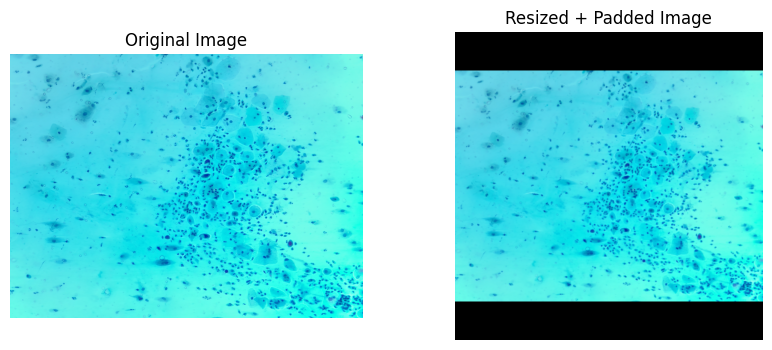

In [15]:
# Testing the transformation

resize_pad = ResizeWithPadding(512)

sample_path = train_df.iloc[0]["image_path"]

image = Image.open(sample_path).convert("RGB")
processed_image = resize_pad(image)

print("Original dimensions:", image.size)
print("Processed dimensions:", processed_image.size)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(processed_image)
plt.title("Resized + Padded Image")
plt.axis("off")

plt.show()

We will create our custom `Pytorch Dataset`.

In [16]:
# Lets establish our class to index mapping using encoding

class_to_idx = {
    class_name: idx
    for idx, class_name in enumerate(classes)
}

print(class_to_idx)

{'ASCUS': 0, 'HSIL': 1, 'LSIL': 2, 'SCC': 3, 'NILM': 4}


In [17]:
# Create the dataset class

class CervicalCytologyDataset(Dataset):

  def __init__(self, dataframe, transform=None):
    self.dataframe = dataframe.reset_index(drop=True)
    self.transform = transform

  def __len__(self):
    return len(self.dataframe)

  def __getitem__(self,index):

    image_path = self.dataframe.loc[index, "image_path"]
    label = self.dataframe.loc[index, "label"]

    image = Image.open(image_path).convert("RGB")

    if self.transform:
      image = self.transform(image)

    label = class_to_idx[label]

    return image, label

In [18]:
# Lets instantiate three datasets seperately

train_dataset = CervicalCytologyDataset(
    train_df,
    transform=train_transform
)

val_dataset = CervicalCytologyDataset(
    val_df,
    transform = eval_transform
)

test_dataset = CervicalCytologyDataset(
    test_df,
    transform = eval_transform
)

In [19]:
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))

Training samples: 3896
Validation samples: 835
Testing samples: 835


In [20]:
# Lets configure our data loaders

BATCH_SIZE=16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size = BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size = BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [21]:
# lets inspect a batch here:

images, labels = next(iter(train_loader))

print("Image Batch Shape: ", images.shape)
print("Labels batch Shape: ", labels.shape)
print("Labels: ", labels)

Image Batch Shape:  torch.Size([16, 3, 512, 512])
Labels batch Shape:  torch.Size([16])
Labels:  tensor([0, 1, 1, 1, 2, 2, 3, 1, 3, 4, 4, 3, 2, 2, 3, 4])


MLFlow Experiment Tracking

In [22]:
print("Mlflow Version: ", mlflow.__version__)

Mlflow Version:  3.17.2


In [23]:
# Load Dugshub Authentication

DAGSHUB_USER = "zamanwajahath"
DAGSHUB_REPO = "cervical-cytology-classification"

DAGSHUB_TOKEN = userdata.get("DAGSHUB_TOKEN")

os.environ["MLFLOW_TRACKING_USERNAME"] = DAGSHUB_USER
os.environ["MLFLOW_TRACKING_PASSWORD"] = DAGSHUB_TOKEN

In [24]:
# Lets connect to Dagshub

MLFLOW_TRACKING_URI = (
    f"https://dagshub.com/{DAGSHUB_USER}/{DAGSHUB_REPO}.mlflow"
)

mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)

mlflow.set_experiment(
    "Cervical_Cytology_Classification"
)

print("Tracking URI: ", mlflow.get_tracking_uri())
print("Experiment:", mlflow.get_experiment_by_name(
    "Cervical_Cytology_Classification"
).name)

Tracking URI:  https://dagshub.com/zamanwajahath/cervical-cytology-classification.mlflow
Experiment: Cervical_Cytology_Classification


In [25]:
with mlflow.start_run(run_name="dagshub_verification"):

    mlflow.log_param("project", "Cervical Cytology Classification")
    mlflow.log_param("environment", "Google Colab")

    mlflow.log_metric("connection_status", 1)

    run_id = mlflow.active_run().info.run_id

print("Run ID:", run_id)

🏃 View run dagshub_verification at: https://dagshub.com/zamanwajahath/cervical-cytology-classification.mlflow/#/experiments/0/runs/81ae89a26db040f098e85a284f7893cf
🧪 View experiment at: https://dagshub.com/zamanwajahath/cervical-cytology-classification.mlflow/#/experiments/0
Run ID: 81ae89a26db040f098e85a284f7893cf


In [26]:
# Testing the connection

with mlflow.start_run(run_name="connection_test"):

  mlflow.log_param("project", "Cervical Cytology Classification")
  mlflow.log_param("environment", "Google Colab")

  mlflow.log_metric("connection_status", 1)

print("Succesfully connected to Dagshub MLFlow!")

🏃 View run connection_test at: https://dagshub.com/zamanwajahath/cervical-cytology-classification.mlflow/#/experiments/0/runs/51400a07f51143368a8f18ee2243174b
🧪 View experiment at: https://dagshub.com/zamanwajahath/cervical-cytology-classification.mlflow/#/experiments/0
Succesfully connected to Dagshub MLFlow!


In [27]:
# Lets verify a run

experiment = mlflow.get_experiment_by_name(
    "Cervical_Cytology_Classification"
)

runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id]
)

display(runs[[
    "run_id",
    "tags.mlflow.runName",
    "params.project",
    "params.environment",
    "metrics.connection_status"
]])

,run_id,tags.mlflow.runName,params.project,params.environment,metrics.connection_status
0,51400a07f51143368a8f18ee2243174b,connection_test,Cervical Cytology Classification,Google Colab,1.0
1,81ae89a26db040f098e85a284f7893cf,dagshub_verification,Cervical Cytology Classification,Google Colab,1.0
2,e910d102543047e1a3cf30a98902f3e0,Weighted_CNN_512,None,None,NaN
3,cb598ae42c534083b1a790a6a39987fe,Baseline_CNN_512,None,None,NaN
4,4056cb115d004720ab90a413f1620ff3,connection_test,Cervical Cytology Classification,Google Colab,1.0
5,b5aa4ae1b953449b87433c6d505da0e8,dagshub_verification,Cervical Cytology Classification,Google Colab,1.0


In [28]:
print("Tracking URI:", mlflow.get_tracking_uri())

experiment = mlflow.get_experiment_by_name(
    "Cervical_Cytology_Classification"
)

print("Experiment ID:", experiment.experiment_id)
print("Experiment name:", experiment.name)

Tracking URI: https://dagshub.com/zamanwajahath/cervical-cytology-classification.mlflow
Experiment ID: 0
Experiment name: Cervical_Cytology_Classification


MLFlow is initialized in `DUGSHUB` and Setup is complete.

BASELINE CNN ARCHITECTURE

In [29]:
# Building our baseline cnn network

class BaselineCNN(nn.Module):

  def __init__(self, num_classes=5):

    super(BaselineCNN, self).__init__()

    self.features = nn.Sequential(

        # Block 1
        nn.Conv2d(3, 32, kernel_size=3, padding=1),
        nn.BatchNorm2d(32),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(2),


        # Block 2
        nn.Conv2d(32, 64, kernel_size=3, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(2),

        # Block 3
        nn.Conv2d(64, 128, kernel_size=3, padding=1),
        nn.BatchNorm2d(128),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(2),

        # Block 4
        nn.Conv2d(128, 256, kernel_size=3, padding=1),
        nn.BatchNorm2d(256),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(2)
    )

    self.pool = nn.AdaptiveAvgPool2d((1,1))

    self.classifier = nn.Sequential(
        nn.Flatten(),
        nn.Dropout(0.4),
        nn.Linear(256, num_classes)
    )

  def forward(self, x):

    x = self.features(x)
    x = self.pool(x)
    x = self.classifier(x)

    return x


In [30]:
# Initializing the model

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = BaselineCNN(num_classes=5).to(device)

print(model)
print("Device:", device)

BaselineCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.1, 

In [37]:
# Verifying the Output shape

dummy_input = torch.randn(2, 3, 512, 512).to(device)

output = model(dummy_input)

print("Input Shape: ", dummy_input.shape)
print("Output Shape: ", output.shape)

Input Shape:  torch.Size([2, 3, 512, 512])
Output Shape:  torch.Size([2, 5])


Configure the Training Components

In [32]:
# Define the Loss Function

criterion = nn.CrossEntropyLoss()

In [33]:
# Defining the Optimizer

LEARNING_RATE = 0.001

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

In [34]:
# Defining the Training Parameters

EPOCHS = 20
BATCH_SIZE = 16

In [35]:
# Verifying the Training Parameters

total_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print('Trainable_parameters: ', total_params)

Trainable_parameters:  390661


Training The Baseline CNN Model With MLflow

In [55]:
# Defining the Training Loop

def train_one_epoch(model, train_loader, criterion, optimizer, device):

  model.train()

  running_loss = 0.0
  correct = 0
  total = 0

  for images, labels in train_loader:

    images = images.to(device)
    labels = labels.to(device)

    # Clear Previous Gradients
    optimizer.zero_grad()

    # Forward Propagation
    outputs = model(images)

    # Calculate Loss
    loss = criterion(outputs, labels)

    # Backpropagation
    loss.backward()

    # Update weights
    optimizer.step()


    running_loss += loss.item() * images.size(0)

    _, predicted = torch.max(outputs, 1)

    total += labels.size(0)
    correct += (predicted == labels).sum().item()

  epoch_loss = running_loss / len(train_loader.dataset)
  accuracy = correct / total

  return epoch_loss, accuracy

In [56]:
# Implementing The Validation Function

def validate_one_epoch(model, val_loader, criterion, device):

  model.eval()

  running_loss = 0.0
  correct = 0
  total = 0

  with torch.no_grad():
    for images,labels in val_loader:

      images = images.to(device)
      labels = labels.to(device)

      # Forward Propagation
      outputs = model(images)

      # Calculate Loss
      loss = criterion(outputs, labels)

      running_loss += loss.item() * images.size(0)

      _, predicted = torch.max(outputs, 1)

      total += labels.size(0)
      correct += (predicted == labels).sum().item()

  epoch_loss = running_loss / total
  accuracy = correct / total

  return epoch_loss, accuracy

First MLflow Integrated Training Loop

In [36]:
# Due To a Failed Attempt we will have to bring the model to baseline before retrying

model = BaselineCNN(num_classes=5).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

print("Model and optimizer reinitialized successfully.")

Model and optimizer reinitialized successfully.


Now ideally we must implement model here, but we will configure the checkpointing here first.

In [49]:
import os

# Base checkpoint directory
CHECKPOINT_DIR = (
    "/content/drive/MyDrive/Cervical_Cancer_Project/"
    "checkpoints/training"
)

# Experiment name
EXPERIMENT_NAME = "Baseline_CNN_512" # This will be changed for next training run

# Create experiment-specific directory
EXPERIMENT_DIR = os.path.join(
    CHECKPOINT_DIR,
    EXPERIMENT_NAME
)

os.makedirs(EXPERIMENT_DIR, exist_ok=True)

# Checkpoint paths
LATEST_CHECKPOINT_PATH = os.path.join(
    EXPERIMENT_DIR,
    "latest_checkpoint.pth"
)

BEST_MODEL_PATH = os.path.join(
    EXPERIMENT_DIR,
    "best_model.pth"
)

TRAINING_HISTORY_PATH = os.path.join(
    EXPERIMENT_DIR,
    "training_history.json"
)

print("Experiment:", EXPERIMENT_NAME)
print("Experiment directory:", EXPERIMENT_DIR)
print("Latest checkpoint:", LATEST_CHECKPOINT_PATH)
print("Best model:", BEST_MODEL_PATH)
print("Training history:", TRAINING_HISTORY_PATH)

Experiment: Baseline_CNN_512
Experiment directory: /content/drive/MyDrive/Cervical_Cancer_Project/checkpoints/training/Baseline_CNN_512
Latest checkpoint: /content/drive/MyDrive/Cervical_Cancer_Project/checkpoints/training/Baseline_CNN_512/latest_checkpoint.pth
Best model: /content/drive/MyDrive/Cervical_Cancer_Project/checkpoints/training/Baseline_CNN_512/best_model.pth
Training history: /content/drive/MyDrive/Cervical_Cancer_Project/checkpoints/training/Baseline_CNN_512/training_history.json


In [58]:
# Lets add checkpoint management functions

def save_training_checkpoint(
    model,
    optimizer,
    epoch,
    best_val_loss,
    best_epoch,
    training_history,
    filepath
):

    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "best_val_loss": best_val_loss,
        "best_epoch": best_epoch,
        "training_history": training_history,

        # Random states for reproducibility
        "torch_rng_state": torch.get_rng_state(),
        "numpy_rng_state": np.random.get_state(),
        "python_rng_state": random.getstate()
    }

    if torch.cuda.is_available():
        checkpoint["cuda_rng_state"] = torch.cuda.get_rng_state_all()

    # Atomic checkpoint saving
    temp_path = filepath + ".tmp"

    torch.save(checkpoint, temp_path)

    os.replace(temp_path, filepath)


def load_training_checkpoint(
    model,
    optimizer,
    filepath,
    device
):

    checkpoint = torch.load(
        filepath,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(checkpoint["model_state_dict"])

    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

    # Restore random states
    torch.set_rng_state(checkpoint["torch_rng_state"])

    np.random.set_state(checkpoint["numpy_rng_state"])

    random.setstate(checkpoint["python_rng_state"])

    if "cuda_rng_state" in checkpoint and torch.cuda.is_available():
        torch.cuda.set_rng_state_all(checkpoint["cuda_rng_state"])

    print(f"Checkpoint restored from: {filepath}")
    print(f"Last completed epoch: {checkpoint['epoch']}")

    return checkpoint

In [50]:
import os

print("Experiment:", EXPERIMENT_NAME)
print("Checkpoint directory:", EXPERIMENT_DIR)

print("\nDirectory exists:", os.path.isdir(EXPERIMENT_DIR))

if os.path.isdir(EXPERIMENT_DIR):
    print("\nExisting files:")
    files = os.listdir(EXPERIMENT_DIR)

    if files:
        for file in files:
            print("-", file)
    else:
        print("Directory is empty.")

print("\nCheckpoint paths:")
print("Latest:", LATEST_CHECKPOINT_PATH)
print("Best:", BEST_MODEL_PATH)
print("History:", TRAINING_HISTORY_PATH)

Experiment: Baseline_CNN_512
Checkpoint directory: /content/drive/MyDrive/Cervical_Cancer_Project/checkpoints/training/Baseline_CNN_512

Directory exists: True

Existing files:
Directory is empty.

Checkpoint paths:
Latest: /content/drive/MyDrive/Cervical_Cancer_Project/checkpoints/training/Baseline_CNN_512/latest_checkpoint.pth
Best: /content/drive/MyDrive/Cervical_Cancer_Project/checkpoints/training/Baseline_CNN_512/best_model.pth
History: /content/drive/MyDrive/Cervical_Cancer_Project/checkpoints/training/Baseline_CNN_512/training_history.json


In [51]:
import copy
import torch
import numpy as np
import random

test_checkpoint_path = os.path.join(
    EXPERIMENT_DIR,
    "checkpoint_test.pth"
)

test_checkpoint = {
    "epoch": 0,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "best_val_loss": float("inf"),
    "best_epoch": 0,
    "torch_rng_state": torch.get_rng_state(),
    "numpy_rng_state": np.random.get_state(),
    "python_rng_state": random.getstate()
}

if torch.cuda.is_available():
    test_checkpoint["cuda_rng_state"] = torch.cuda.get_rng_state_all()

torch.save(test_checkpoint, test_checkpoint_path)

print("Test checkpoint saved:", os.path.exists(test_checkpoint_path))
print("File size:", round(os.path.getsize(test_checkpoint_path) / 1024, 2), "KB")

Test checkpoint saved: True
File size: 1554.11 KB


In [52]:
loaded_checkpoint = torch.load(
    test_checkpoint_path,
    map_location="cpu",
    weights_only=False
)

# Restore model state
model.load_state_dict(loaded_checkpoint["model_state_dict"])

# Restore optimizer state
optimizer.load_state_dict(loaded_checkpoint["optimizer_state_dict"])

# Restore random states
torch.set_rng_state(loaded_checkpoint["torch_rng_state"])
np.random.set_state(loaded_checkpoint["numpy_rng_state"])
random.setstate(loaded_checkpoint["python_rng_state"])

print("Checkpoint loaded successfully!")
print("Saved epoch:", loaded_checkpoint["epoch"])
print("Best validation loss:", loaded_checkpoint["best_val_loss"])
print("Model state restored:", True)
print("Optimizer state restored:", True)

Checkpoint loaded successfully!
Saved epoch: 0
Best validation loss: inf
Model state restored: True
Optimizer state restored: True


In [53]:
print("Checkpoint keys:")
for key in loaded_checkpoint.keys():
    print("-", key)

print("\nModel parameters:", len(loaded_checkpoint["model_state_dict"]))
print("Optimizer state entries:", len(loaded_checkpoint["optimizer_state_dict"]["state"]))
print("PyTorch RNG state:", "cuda_rng_state" in loaded_checkpoint or "torch_rng_state" in loaded_checkpoint)
print("NumPy RNG state:", "numpy_rng_state" in loaded_checkpoint)
print("Python RNG state:", "python_rng_state" in loaded_checkpoint)

Checkpoint keys:
- epoch
- model_state_dict
- optimizer_state_dict
- best_val_loss
- best_epoch
- torch_rng_state
- numpy_rng_state
- python_rng_state
- cuda_rng_state

Model parameters: 30
Optimizer state entries: 0
PyTorch RNG state: True
NumPy RNG state: True
Python RNG state: True


In [54]:
# Create a temporary model and optimizer
test_model = copy.deepcopy(model)
test_optimizer = torch.optim.Adam(
    test_model.parameters(),
    lr=0.001
)

test_device = next(test_model.parameters()).device
test_model.train()

# Generate synthetic data
dummy_images = torch.randn(2, 3, 32, 32).to(test_device)
dummy_labels = torch.tensor([0, 1]).to(test_device)

# Perform one training step
test_optimizer.zero_grad()

outputs = test_model(dummy_images)
loss = criterion(outputs, dummy_labels)

loss.backward()
test_optimizer.step()

# Save the updated states
interruption_checkpoint = {
    "epoch": 1,
    "model_state_dict": test_model.state_dict(),
    "optimizer_state_dict": test_optimizer.state_dict()
}

torch.save(
    interruption_checkpoint,
    test_checkpoint_path
)

print("Simulated training step completed.")
print("Optimizer state entries:",
      len(test_optimizer.state_dict()["state"]))

Simulated training step completed.
Optimizer state entries: 18


In [55]:
# Create a fresh model and optimizer
recovered_model = copy.deepcopy(model)

recovered_optimizer = torch.optim.Adam(
    recovered_model.parameters(),
    lr=0.001
)

# Load checkpoint
checkpoint = torch.load(
    test_checkpoint_path,
    map_location="cpu",
    weights_only=False
)

recovered_model.load_state_dict(
    checkpoint["model_state_dict"]
)

recovered_optimizer.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

print("Recovery successful!")
print("Recovered epoch:", checkpoint["epoch"])
print(
    "Recovered optimizer state entries:",
    len(recovered_optimizer.state_dict()["state"])
)

Recovery successful!
Recovered epoch: 1
Recovered optimizer state entries: 18


We have implemented checkpointing and tested it as well. Now we will train our first MLflow integrated loop.

In [56]:
# Experiment Configuration

best_val_loss = float("inf")
best_epoch = 0

training_history = []

start_epoch = 0

# Check whether an existing checkpoint is available
if os.path.exists(LATEST_CHECKPOINT_PATH):

    print("Existing checkpoint detected. Resuming training...")

    checkpoint = load_training_checkpoint(
        model,
        optimizer,
        LATEST_CHECKPOINT_PATH,
        device
    )

    start_epoch = checkpoint["epoch"] + 1

    best_val_loss = checkpoint["best_val_loss"]

    best_epoch = checkpoint["best_epoch"]

    training_history = checkpoint["training_history"]

else:

    print("No previous checkpoint found. Starting fresh training.")

    best_model_weights = copy.deepcopy(model.state_dict())


with mlflow.start_run(run_name=EXPERIMENT_NAME):

    # Log hyperparameters
    mlflow.log_params({
        "model": "BaselineCNN",
        "image_size": IMG_SIZE,
        "batch_size": BATCH_SIZE,
        "epochs": EPOCHS,
        "learning_rate": LEARNING_RATE,
        "optimizer": "Adam",
        "loss_function": "CrossEntropyLoss",
        "trainable_parameters": total_params,
        "experiment_name": EXPERIMENT_NAME
    })

    if start_epoch > 0:
        mlflow.log_param("resumed_from_epoch", start_epoch)

    start_time = time.time()

    for epoch in range(start_epoch, EPOCHS):

        # Training
        train_loss, train_acc = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            device
        )

        # Validation
        val_loss, val_acc = validate_one_epoch(
            model,
            val_loader,
            criterion,
            device
        )

        # Record training history
        epoch_metrics = {
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "val_loss": val_loss,
            "val_accuracy": val_acc
        }

        training_history.append(epoch_metrics)

        # Log metrics to MLflow
        mlflow.log_metrics(
            {
                "train_loss": train_loss,
                "train_accuracy": train_acc,
                "val_loss": val_loss,
                "val_accuracy": val_acc
            },
            step=epoch + 1
        )

        # Check whether this is the best model
        if val_loss < best_val_loss:

            best_val_loss = val_loss
            best_epoch = epoch + 1

            best_model_weights = copy.deepcopy(model.state_dict())

            torch.save(
                {
                    "model_state_dict": best_model_weights,
                    "epoch": best_epoch,
                    "best_val_loss": best_val_loss
                },
                BEST_MODEL_PATH + ".tmp"
            )

            os.replace(
                BEST_MODEL_PATH + ".tmp",
                BEST_MODEL_PATH
            )

        # Save latest training checkpoint after every epoch
        save_training_checkpoint(
            model=model,
            optimizer=optimizer,
            epoch=epoch,
            best_val_loss=best_val_loss,
            best_epoch=best_epoch,
            training_history=training_history,
            filepath=LATEST_CHECKPOINT_PATH
        )

        # Save training history
        with open(TRAINING_HISTORY_PATH + ".tmp", "w") as file:
            json.dump(training_history, file, indent=4)

        os.replace(
            TRAINING_HISTORY_PATH + ".tmp",
            TRAINING_HISTORY_PATH
        )

        print(
            f"Epoch [{epoch+1}/{EPOCHS}] "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.4f}"
        )

        print("Checkpoint saved successfully.")

    training_time = time.time() - start_time

    mlflow.log_metric(
        "training_time_seconds",
        training_time
    )

    mlflow.log_metric(
        "best_val_loss",
        best_val_loss
    )

    mlflow.log_metric(
        "best_epoch",
        best_epoch
    )

    print(f"\nTraining completed in {training_time/60:.2f} minutes.")

    print(f"Best Validation Loss: {best_val_loss:.4f}")

    print(f"Best Epoch: {best_epoch}")


# Restore the best model weights
best_checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(best_checkpoint["model_state_dict"])

print("\nBest model weights restored successfully.")

No previous checkpoint found. Starting fresh training.
Epoch [1/20] Train Loss: 1.3742 | Train Acc: 0.4161 | Val Loss: 1.7819 | Val Acc: 0.2431
Checkpoint saved successfully.
Epoch [2/20] Train Loss: 1.2319 | Train Acc: 0.4882 | Val Loss: 1.9130 | Val Acc: 0.2802
Checkpoint saved successfully.
Epoch [3/20] Train Loss: 1.1817 | Train Acc: 0.5098 | Val Loss: 1.6805 | Val Acc: 0.2970
Checkpoint saved successfully.
Epoch [4/20] Train Loss: 1.1473 | Train Acc: 0.5167 | Val Loss: 1.7023 | Val Acc: 0.3269
Checkpoint saved successfully.
Epoch [5/20] Train Loss: 1.1343 | Train Acc: 0.5280 | Val Loss: 1.6313 | Val Acc: 0.3234
Checkpoint saved successfully.
Epoch [6/20] Train Loss: 1.1316 | Train Acc: 0.5303 | Val Loss: 1.6803 | Val Acc: 0.3269
Checkpoint saved successfully.
Epoch [7/20] Train Loss: 1.1168 | Train Acc: 0.5436 | Val Loss: 1.5975 | Val Acc: 0.3413
Checkpoint saved successfully.
Epoch [8/20] Train Loss: 1.0955 | Train Acc: 0.5560 | Val Loss: 1.6092 | Val Acc: 0.3246
Checkpoint saved

In [58]:
model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)

        outputs = model(images)

        predictions = torch.argmax(outputs, dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

print("Validation predictions generated successfully.")
print("Total samples:", len(all_labels))

Validation predictions generated successfully.
Total samples: 835


In [59]:
 # Accuracy
accuracy = accuracy_score(all_labels, all_predictions)

# Macro averages
macro_precision = precision_score(
    all_labels, all_predictions,
    average="macro", zero_division=0
)

macro_recall = recall_score(
    all_labels, all_predictions,
    average="macro", zero_division=0
)

macro_f1 = f1_score(
    all_labels, all_predictions,
    average="macro", zero_division=0
)

# Weighted F1
weighted_f1 = f1_score(
    all_labels, all_predictions,
    average="weighted", zero_division=0
)

print("VALIDATION METRICS")
print("-------------------------")
print(f"Accuracy:         {accuracy:.4f}")
print(f"Macro Precision:  {macro_precision:.4f}")
print(f"Macro Recall:     {macro_recall:.4f}")
print(f"Macro F1-score:   {macro_f1:.4f}")
print(f"Weighted F1:      {weighted_f1:.4f}")

VALIDATION METRICS
-------------------------
Accuracy:         0.4012
Macro Precision:  0.4842
Macro Recall:     0.2970
Macro F1-score:   0.2574
Weighted F1:      0.3413


In [61]:
print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=classes,
        zero_division=0
    )
)

              precision    recall  f1-score   support

       ASCUS       0.21      0.03      0.05        97
        HSIL       0.35      0.82      0.49       217
        LSIL       0.31      0.12      0.17       184
         SCC       1.00      0.03      0.06        69
        NILM       0.55      0.49      0.51       268

    accuracy                           0.40       835
   macro avg       0.48      0.30      0.26       835
weighted avg       0.44      0.40      0.34       835



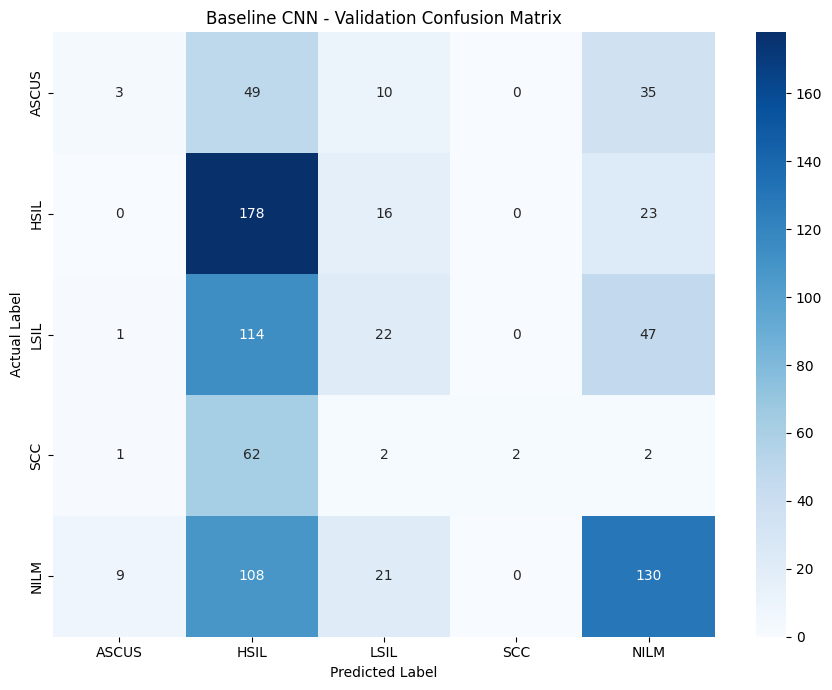

In [63]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(all_labels, all_predictions)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Baseline CNN - Validation Confusion Matrix")

plt.tight_layout()
plt.show()

The model appears heavily biased towards HSIL class. Now we will implement class weighted loss function.

In [66]:
print("Dataset attributes:")
print(train_loader.dataset.__dict__.keys())

print("\nClass names:")
print(classes)

print("\nTraining dataset size:")
print(len(train_loader.dataset))

Dataset attributes:
dict_keys(['dataframe', 'transform'])

Class names:
['ASCUS', 'HSIL', 'LSIL', 'SCC', 'NILM']

Training dataset size:
3896


In [67]:

print("Columns:")
print(train_loader.dataset.dataframe.columns.tolist())

print("\nFirst five rows:")
display(train_loader.dataset.dataframe.head())

print("\nData types:")
print(train_loader.dataset.dataframe.dtypes)

Columns:
['image_path', 'label']

First five rows:


,image_path,label
0,/content/drive/MyDrive/Cervical_Cancer_Project...,NILM
1,/content/drive/MyDrive/Cervical_Cancer_Project...,HSIL
2,/content/drive/MyDrive/Cervical_Cancer_Project...,LSIL
3,/content/drive/MyDrive/Cervical_Cancer_Project...,NILM
4,/content/drive/MyDrive/Cervical_Cancer_Project...,ASCUS



Data types:
image_path    object
label         object
dtype: object


In [69]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
import torch

# Extract training labels
train_labels = train_loader.dataset.dataframe["label"].values

# Calculate class weights
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array(classes),
    y=train_labels
)

# Convert weights into a PyTorch tensor
class_weights = torch.tensor(
    weights,
    dtype=torch.float32
).to(device)

# Display results
for class_name, weight in zip(classes, weights):
    print(f"{class_name}: {weight:.4f}")

print("\nClass weights tensor:", class_weights)

ASCUS: 1.7239
HSIL: 0.7722
LSIL: 0.9050
SCC: 2.4274
NILM: 0.6219

Class weights tensor: tensor([1.7239, 0.7722, 0.9050, 2.4274, 0.6219], device='cuda:0')


We start the Second Run

In [70]:
criterion = nn.CrossEntropyLoss(weight=class_weights)

print("Weighted CrossEntropyLoss configured successfully.")

Weighted CrossEntropyLoss configured successfully.


In [71]:
EXPERIMENT_NAME = "Weighted_CNN_512"

EXPERIMENT_DIR = os.path.join(
    CHECKPOINT_DIR,
    EXPERIMENT_NAME
)

os.makedirs(EXPERIMENT_DIR, exist_ok=True)

LATEST_CHECKPOINT_PATH = os.path.join(
    EXPERIMENT_DIR,
    "latest_checkpoint.pth"
)

BEST_MODEL_PATH = os.path.join(
    EXPERIMENT_DIR,
    "best_model.pth"
)

TRAINING_HISTORY_PATH = os.path.join(
    EXPERIMENT_DIR,
    "training_history.json"
)

print("Experiment 2 directory:", EXPERIMENT_DIR)
print("Directory exists:", os.path.exists(EXPERIMENT_DIR))

Experiment 2 directory: /content/drive/MyDrive/Cervical_Cancer_Project/checkpoints/training/Weighted_CNN_512
Directory exists: True


In [73]:
model = BaselineCNN(num_classes=len(classes)).to(device)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Experiment 2 model initialized.")
print("Optimizer: Adam")
print("Learning rate: 0.001")
print("Criterion: Weighted CrossEntropyLoss")

Experiment 2 model initialized.
Optimizer: Adam
Learning rate: 0.001
Criterion: Weighted CrossEntropyLoss


In [74]:
EPOCHS = 20
BATCH_SIZE = 16
LEARNING_RATE = 0.001

best_val_loss = float("inf")
best_epoch = 0
training_history = []
start_epoch = 0

print("Experiment 2 configuration:")
print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)
print("Class weighting: Enabled")

Experiment 2 configuration:
Epochs: 20
Batch size: 16
Learning rate: 0.001
Class weighting: Enabled


In [75]:
print("Model device:", next(model.parameters()).device)
print("Loss function:", criterion)
print("Optimizer:", optimizer)
print("Checkpoint directory:", EXPERIMENT_DIR)
print("Latest checkpoint:", LATEST_CHECKPOINT_PATH)
print("Best model:", BEST_MODEL_PATH)
print("Training epochs:", EPOCHS)
print("Starting epoch:", start_epoch)

Model device: cuda:0
Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)
Checkpoint directory: /content/drive/MyDrive/Cervical_Cancer_Project/checkpoints/training/Weighted_CNN_512
Latest checkpoint: /content/drive/MyDrive/Cervical_Cancer_Project/checkpoints/training/Weighted_CNN_512/latest_checkpoint.pth
Best model: /content/drive/MyDrive/Cervical_Cancer_Project/checkpoints/training/Weighted_CNN_512/best_model.pth
Training epochs: 20
Starting epoch: 0


In [77]:
# Experiment Configuration

best_val_loss = float("inf")
best_epoch = 0

training_history = []

start_epoch = 0

# Check whether an existing checkpoint is available
if os.path.exists(LATEST_CHECKPOINT_PATH):

    print("Existing checkpoint detected. Resuming training...")

    checkpoint = load_training_checkpoint(
        model,
        optimizer,
        LATEST_CHECKPOINT_PATH,
        device
    )

    start_epoch = checkpoint["epoch"] + 1

    best_val_loss = checkpoint["best_val_loss"]

    best_epoch = checkpoint["best_epoch"]

    training_history = checkpoint["training_history"]

else:

    print("No previous checkpoint found. Starting fresh training.")

    best_model_weights = copy.deepcopy(model.state_dict())


with mlflow.start_run(run_name=EXPERIMENT_NAME):

    # Log hyperparameters
    mlflow.log_params({
        "model": "BaselineCNN",
        "image_size": IMG_SIZE,
        "batch_size": BATCH_SIZE,
        "epochs": EPOCHS,
        "learning_rate": LEARNING_RATE,
        "optimizer": "Adam",
        "loss_function": "WeightedCrossEntropyLoss",
        "class_weights": str(weights.tolist()),
        "trainable_parameters": total_params,
        "experiment_name": EXPERIMENT_NAME
    })

    if start_epoch > 0:
        mlflow.log_param("resumed_from_epoch", start_epoch)

    start_time = time.time()

    for epoch in range(start_epoch, EPOCHS):

        # Training
        train_loss, train_acc = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            device
        )

        # Validation
        val_loss, val_acc = validate_one_epoch(
            model,
            val_loader,
            criterion,
            device
        )

        # Record training history
        epoch_metrics = {
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "val_loss": val_loss,
            "val_accuracy": val_acc
        }

        training_history.append(epoch_metrics)

        # Log metrics to MLflow
        mlflow.log_metrics(
            {
                "train_loss": train_loss,
                "train_accuracy": train_acc,
                "val_loss": val_loss,
                "val_accuracy": val_acc
            },
            step=epoch + 1
        )

        # Check whether this is the best model
        if val_loss < best_val_loss:

            best_val_loss = val_loss
            best_epoch = epoch + 1

            best_model_weights = copy.deepcopy(model.state_dict())

            torch.save(
                {
                    "model_state_dict": best_model_weights,
                    "epoch": best_epoch,
                    "best_val_loss": best_val_loss
                },
                BEST_MODEL_PATH + ".tmp"
            )

            os.replace(
                BEST_MODEL_PATH + ".tmp",
                BEST_MODEL_PATH
            )

        # Save latest training checkpoint after every epoch
        save_training_checkpoint(
            model=model,
            optimizer=optimizer,
            epoch=epoch,
            best_val_loss=best_val_loss,
            best_epoch=best_epoch,
            training_history=training_history,
            filepath=LATEST_CHECKPOINT_PATH
        )

        # Save training history
        with open(TRAINING_HISTORY_PATH + ".tmp", "w") as file:
            json.dump(training_history, file, indent=4)

        os.replace(
            TRAINING_HISTORY_PATH + ".tmp",
            TRAINING_HISTORY_PATH
        )

        print(
            f"Epoch [{epoch+1}/{EPOCHS}] "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.4f}"
        )

        print("Checkpoint saved successfully.")

    training_time = time.time() - start_time

    mlflow.log_metric(
        "training_time_seconds",
        training_time
    )

    mlflow.log_metric(
        "best_val_loss",
        best_val_loss
    )

    mlflow.log_metric(
        "best_epoch",
        best_epoch
    )

    print(f"\nTraining completed in {training_time/60:.2f} minutes.")

    print(f"Best Validation Loss: {best_val_loss:.4f}")

    print(f"Best Epoch: {best_epoch}")


# Restore the best model weights
best_checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(best_checkpoint["model_state_dict"])

print("\nBest model weights restored successfully.")

No previous checkpoint found. Starting fresh training.
Epoch [1/20] Train Loss: 1.4646 | Train Acc: 0.3534 | Val Loss: 1.8770 | Val Acc: 0.2479
Checkpoint saved successfully.
Epoch [2/20] Train Loss: 1.3534 | Train Acc: 0.4125 | Val Loss: 2.0143 | Val Acc: 0.1186
Checkpoint saved successfully.
Epoch [3/20] Train Loss: 1.3162 | Train Acc: 0.4376 | Val Loss: 2.2085 | Val Acc: 0.2132
Checkpoint saved successfully.
Epoch [4/20] Train Loss: 1.2615 | Train Acc: 0.4507 | Val Loss: 2.1260 | Val Acc: 0.2563
Checkpoint saved successfully.
Epoch [5/20] Train Loss: 1.2597 | Train Acc: 0.4461 | Val Loss: 2.0107 | Val Acc: 0.2144
Checkpoint saved successfully.
Epoch [6/20] Train Loss: 1.2287 | Train Acc: 0.4646 | Val Loss: 1.9676 | Val Acc: 0.2000
Checkpoint saved successfully.
Epoch [7/20] Train Loss: 1.2007 | Train Acc: 0.4800 | Val Loss: 1.8406 | Val Acc: 0.2778
Checkpoint saved successfully.
Epoch [8/20] Train Loss: 1.2054 | Train Acc: 0.4738 | Val Loss: 2.0885 | Val Acc: 0.2790
Checkpoint saved

In [37]:
model.eval()

all_labels_exp2 = []
all_predictions_exp2 = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)

        outputs = model(images)

        predictions = torch.argmax(outputs, dim=1)

        all_labels_exp2.extend(labels.cpu().numpy())
        all_predictions_exp2.extend(predictions.cpu().numpy())

print("Experiment 2 validation predictions generated.")
print("Total samples:", len(all_labels_exp2))

Experiment 2 validation predictions generated.
Total samples: 835


In [38]:
accuracy_exp2 = accuracy_score(
    all_labels_exp2,
    all_predictions_exp2
)

macro_precision_exp2 = precision_score(
    all_labels_exp2,
    all_predictions_exp2,
    average="macro",
    zero_division=0
)

macro_recall_exp2 = recall_score(
    all_labels_exp2,
    all_predictions_exp2,
    average="macro",
    zero_division=0
)

macro_f1_exp2 = f1_score(
    all_labels_exp2,
    all_predictions_exp2,
    average="macro",
    zero_division=0
)

weighted_f1_exp2 = f1_score(
    all_labels_exp2,
    all_predictions_exp2,
    average="weighted",
    zero_division=0
)

print("EXPERIMENT 2 - VALIDATION METRICS")
print("--------------------------------")
print(f"Accuracy:         {accuracy_exp2:.4f}")
print(f"Macro Precision:  {macro_precision_exp2:.4f}")
print(f"Macro Recall:     {macro_recall_exp2:.4f}")
print(f"Macro F1-score:   {macro_f1_exp2:.4f}")
print(f"Weighted F1:      {weighted_f1_exp2:.4f}")

EXPERIMENT 2 - VALIDATION METRICS
--------------------------------
Accuracy:         0.2599
Macro Precision:  0.0520
Macro Recall:     0.2000
Macro F1-score:   0.0825
Weighted F1:      0.1072


In [40]:
print(
    classification_report(
        all_labels_exp2,
        all_predictions_exp2,
        target_names=classes,
        zero_division=0
    )
)

              precision    recall  f1-score   support

       ASCUS       0.00      0.00      0.00        97
        HSIL       0.26      1.00      0.41       217
        LSIL       0.00      0.00      0.00       184
         SCC       0.00      0.00      0.00        69
        NILM       0.00      0.00      0.00       268

    accuracy                           0.26       835
   macro avg       0.05      0.20      0.08       835
weighted avg       0.07      0.26      0.11       835



Training Attempt 3

In [41]:
IMG_SIZE = 1024
BATCH_SIZE = 4

In [42]:
resize_pad = ResizeWithPadding(IMG_SIZE)

train_transform = transforms.Compose([
    resize_pad,
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    resize_pad,
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("1024x1024 transforms configured successfully.")

1024x1024 transforms configured successfully.


In [43]:
train_dataset = CervicalCytologyDataset(
    train_loader.dataset.dataframe,
    transform=train_transform
)

val_dataset = CervicalCytologyDataset(
    val_loader.dataset.dataframe,
    transform=eval_transform
)

test_dataset = CervicalCytologyDataset(
    test_loader.dataset.dataframe,
    transform=eval_transform
)

print("Datasets recreated successfully.")
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

Datasets recreated successfully.
Training samples: 3896
Validation samples: 835
Test samples: 835


In [44]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("DataLoaders created successfully.")
print("Batch size:", BATCH_SIZE)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

DataLoaders created successfully.
Batch size: 4
Training batches: 974
Validation batches: 209
Test batches: 209


In [45]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image data type:", images.dtype)
print("Device:", images.device)

Image batch shape: torch.Size([4, 3, 1024, 1024])
Label batch shape: torch.Size([4])
Image data type: torch.float32
Device: cpu


In [46]:
model = BaselineCNN(num_classes=len(classes)).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

# Move one batch to GPU
images = images.to(device)
labels = labels.to(device)

# Forward pass
outputs = model(images)
loss = criterion(outputs, labels)

# Backward pass
optimizer.zero_grad()
loss.backward()
optimizer.step()

print("GPU forward and backward pass successful.")
print("Output shape:", outputs.shape)
print("Loss:", loss.item())

print(
    "GPU memory allocated:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)

GPU forward and backward pass successful.
Output shape: torch.Size([4, 5])
Loss: 1.6213093996047974
GPU memory allocated: 0.07 GB


In [47]:
!nvidia-smi

Sun Nov  1 07:47:25 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   35C    P0             50W /  400W |    5962MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [50]:
EXPERIMENT_NAME = "Baseline_CNN_1024"

EXPERIMENT_DIR = os.path.join(
    CHECKPOINT_DIR,
    EXPERIMENT_NAME
)

os.makedirs(EXPERIMENT_DIR, exist_ok=True)

LATEST_CHECKPOINT_PATH = os.path.join(
    EXPERIMENT_DIR,
    "latest_checkpoint.pth"
)

BEST_MODEL_PATH = os.path.join(
    EXPERIMENT_DIR,
    "best_model.pth"
)

TRAINING_HISTORY_PATH = os.path.join(
    EXPERIMENT_DIR,
    "training_history.json"
)

print("Experiment:", EXPERIMENT_NAME)
print("Checkpoint directory:", EXPERIMENT_DIR)
print("Directory exists:", os.path.exists(EXPERIMENT_DIR))

Experiment: Baseline_CNN_1024
Checkpoint directory: /content/drive/MyDrive/Cervical_Cancer_Project/checkpoints/training/Baseline_CNN_1024
Directory exists: True


In [52]:
# Experiment configuration
EPOCHS = 20
LEARNING_RATE = 0.001

# Fresh model
model = BaselineCNN(
    num_classes=len(classes)
).to(device)

# Standard Cross Entropy Loss (no class weighting)
criterion = nn.CrossEntropyLoss()

# Fresh optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

# Count trainable parameters
trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Experiment:", EXPERIMENT_NAME)
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Loss function: CrossEntropyLoss")
print("Optimizer: Adam")
print("Trainable parameters:", f"{trainable_params:,}")
print("Model device:", next(model.parameters()).device)

Experiment: Baseline_CNN_1024
Image size: 1024
Batch size: 4
Epochs: 20
Learning rate: 0.001
Loss function: CrossEntropyLoss
Optimizer: Adam
Trainable parameters: 390,661
Model device: cuda:0


In [53]:
mlflow.set_experiment(EXPERIMENT_NAME)

print("MLflow experiment:", EXPERIMENT_NAME)
print("Tracking URI:", mlflow.get_tracking_uri())

2026/11/01 07:49:07 INFO mlflow.tracking.fluent: Experiment with name 'Baseline_CNN_1024' does not exist. Creating a new experiment.


MLflow experiment: Baseline_CNN_1024
Tracking URI: https://dagshub.com/zamanwajahath/cervical-cytology-classification.mlflow


In [59]:
# Experiment Configuration

best_val_loss = float("inf")
best_epoch = 0

training_history = []

start_epoch = 0

# Check whether an existing checkpoint is available
if os.path.exists(LATEST_CHECKPOINT_PATH):

    print("Existing checkpoint detected. Resuming training...")

    checkpoint = load_training_checkpoint(
        model,
        optimizer,
        LATEST_CHECKPOINT_PATH,
        device
    )

    start_epoch = checkpoint["epoch"] + 1

    best_val_loss = checkpoint["best_val_loss"]

    best_epoch = checkpoint["best_epoch"]

    training_history = checkpoint["training_history"]

else:

    print("No previous checkpoint found. Starting fresh training.")

    best_model_weights = copy.deepcopy(model.state_dict())


with mlflow.start_run(run_name=EXPERIMENT_NAME):

    # Log hyperparameters
    mlflow.log_params({
        "model": "BaselineCNN",
        "image_size": IMG_SIZE,
        "batch_size": BATCH_SIZE,
        "epochs": EPOCHS,
        "learning_rate": LEARNING_RATE,
        "optimizer": "Adam",
        "loss_function": "CrossEntropyLoss",
        "trainable_parameters": trainable_params,
        "experiment_name": EXPERIMENT_NAME
    })

    if start_epoch > 0:
        mlflow.log_param("resumed_from_epoch", start_epoch)

    start_time = time.time()

    for epoch in range(start_epoch, EPOCHS):

        # Training
        train_loss, train_acc = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            device
        )

        # Validation
        val_loss, val_acc = validate_one_epoch(
            model,
            val_loader,
            criterion,
            device
        )

        # Record training history
        epoch_metrics = {
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "val_loss": val_loss,
            "val_accuracy": val_acc
        }

        training_history.append(epoch_metrics)

        # Log metrics to MLflow
        mlflow.log_metrics(
            {
                "train_loss": train_loss,
                "train_accuracy": train_acc,
                "val_loss": val_loss,
                "val_accuracy": val_acc
            },
            step=epoch + 1
        )

        # Check whether this is the best model
        if val_loss < best_val_loss:

            best_val_loss = val_loss
            best_epoch = epoch + 1

            best_model_weights = copy.deepcopy(model.state_dict())

            torch.save(
                {
                    "model_state_dict": best_model_weights,
                    "epoch": best_epoch,
                    "best_val_loss": best_val_loss
                },
                BEST_MODEL_PATH + ".tmp"
            )

            os.replace(
                BEST_MODEL_PATH + ".tmp",
                BEST_MODEL_PATH
            )

        # Save latest training checkpoint after every epoch
        save_training_checkpoint(
            model=model,
            optimizer=optimizer,
            epoch=epoch,
            best_val_loss=best_val_loss,
            best_epoch=best_epoch,
            training_history=training_history,
            filepath=LATEST_CHECKPOINT_PATH
        )

        # Save training history
        with open(TRAINING_HISTORY_PATH + ".tmp", "w") as file:
            json.dump(training_history, file, indent=4)

        os.replace(
            TRAINING_HISTORY_PATH + ".tmp",
            TRAINING_HISTORY_PATH
        )

        print(
            f"Epoch [{epoch+1}/{EPOCHS}] "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.4f}"
        )

        print("Checkpoint saved successfully.")

    training_time = time.time() - start_time

    mlflow.log_metric(
        "training_time_seconds",
        training_time
    )

    mlflow.log_metric(
        "best_val_loss",
        best_val_loss
    )

    mlflow.log_metric(
        "best_epoch",
        best_epoch
    )

    print(f"\nTraining completed in {training_time/60:.2f} minutes.")

    print(f"Best Validation Loss: {best_val_loss:.4f}")

    print(f"Best Epoch: {best_epoch}")


# Restore the best model weights
best_checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(best_checkpoint["model_state_dict"])

print("\nBest model weights restored successfully.")

No previous checkpoint found. Starting fresh training.
Epoch [1/20] Train Loss: 1.4059 | Train Acc: 0.4104 | Val Loss: 1.2779 | Val Acc: 0.4132
Checkpoint saved successfully.
Epoch [2/20] Train Loss: 1.3659 | Train Acc: 0.4376 | Val Loss: 1.2325 | Val Acc: 0.4982
Checkpoint saved successfully.
Epoch [3/20] Train Loss: 1.3472 | Train Acc: 0.4430 | Val Loss: 1.2723 | Val Acc: 0.4874
Checkpoint saved successfully.
Epoch [4/20] Train Loss: 1.3234 | Train Acc: 0.4443 | Val Loss: 1.2674 | Val Acc: 0.4766
Checkpoint saved successfully.
Epoch [5/20] Train Loss: 1.3055 | Train Acc: 0.4607 | Val Loss: 1.2104 | Val Acc: 0.5066
Checkpoint saved successfully.
Epoch [6/20] Train Loss: 1.3010 | Train Acc: 0.4592 | Val Loss: 1.2034 | Val Acc: 0.5210
Checkpoint saved successfully.
Epoch [7/20] Train Loss: 1.2878 | Train Acc: 0.4725 | Val Loss: 1.2406 | Val Acc: 0.5042
Checkpoint saved successfully.
Epoch [8/20] Train Loss: 1.2731 | Train Acc: 0.4795 | Val Loss: 1.2015 | Val Acc: 0.5198
Checkpoint saved

In [60]:
model.eval()

all_labels_exp3 = []
all_predictions_exp3 = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)

        outputs = model(images)

        predictions = torch.argmax(outputs, dim=1)

        all_labels_exp3.extend(labels.cpu().numpy())
        all_predictions_exp3.extend(predictions.cpu().numpy())

print("Validation predictions generated successfully.")
print("Total predictions:", len(all_predictions_exp3))

Validation predictions generated successfully.
Total predictions: 835


In [62]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("EXPERIMENT 3 — BASELINE CNN (1024 × 1024)")
print("-" * 55)

print("Accuracy:",
      accuracy_score(all_labels_exp3, all_predictions_exp3))

print("Macro Precision:",
      precision_score(all_labels_exp3, all_predictions_exp3,
                      average="macro", zero_division=0))

print("Macro Recall:",
      recall_score(all_labels_exp3, all_predictions_exp3,
                   average="macro", zero_division=0))

print("Macro F1:",
      f1_score(all_labels_exp3, all_predictions_exp3,
               average="macro", zero_division=0))

print("Weighted F1:",
      f1_score(all_labels_exp3, all_predictions_exp3,
               average="weighted", zero_division=0))

print("\nClassification Report:\n")

print(classification_report(
    all_labels_exp3,
    all_predictions_exp3,
    target_names=classes,
    zero_division=0
))

EXPERIMENT 3 — BASELINE CNN (1024 × 1024)
-------------------------------------------------------
Accuracy: 0.5568862275449101
Macro Precision: 0.6500134922204048
Macro Recall: 0.4729573032967266
Macro F1: 0.45594734529736486
Weighted F1: 0.5159876514259595

Classification Report:

              precision    recall  f1-score   support

       ASCUS       1.00      0.01      0.02        97
        HSIL       0.49      0.41      0.45       217
        LSIL       0.45      0.60      0.52       184
         SCC       0.66      0.48      0.55        69
        NILM       0.65      0.86      0.74       268

    accuracy                           0.56       835
   macro avg       0.65      0.47      0.46       835
weighted avg       0.61      0.56      0.52       835



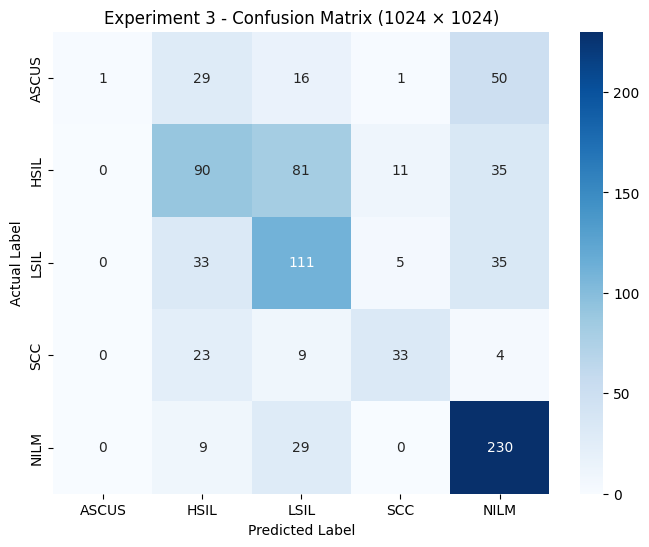

In [64]:
import seaborn as sns

cm_exp3 = confusion_matrix(
    all_labels_exp3,
    all_predictions_exp3
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_exp3,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Experiment 3 - Confusion Matrix (1024 × 1024)")

plt.show()

Transfer Learning

In [68]:
# Load ImageNet pretrained weights
weights = ResNet50_Weights.DEFAULT

model = resnet50(weights=weights)

# Freeze the pretrained backbone
for param in model.parameters():
    param.requires_grad = False

# Replace the original 1000-class classification head
num_features = model.fc.in_features

model.fc = nn.Linear(
    num_features,
    len(classes)
)

# Move model to GPU
model = model.to(device)

# Count trainable parameters
trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel()
    for p in model.parameters()
)

print("Architecture: ResNet50")
print("Pretrained weights: ImageNet")
print("Number of classes:", len(classes))
print("Original FC input features:", num_features)
print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")
print("Device:", next(model.parameters()).device)

Architecture: ResNet50
Pretrained weights: ImageNet
Number of classes: 5
Original FC input features: 2048
Total parameters: 23,518,277
Trainable parameters: 10,245
Device: cuda:0


In [81]:
IMG_SIZE = 512
BATCH_SIZE = 16

resize_pad = ResizeWithPadding(IMG_SIZE)

train_transform = transforms.Compose([
    resize_pad,
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    resize_pad,
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_dataset = CervicalCytologyDataset(
    train_loader.dataset.dataframe,
    transform=train_transform
)

val_dataset = CervicalCytologyDataset(
    val_loader.dataset.dataframe,
    transform=eval_transform
)

test_dataset = CervicalCytologyDataset(
    test_loader.dataset.dataframe,
    transform=eval_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Image size: 512
Batch size: 16
Train: 3896
Validation: 835
Test: 835


In [82]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Data type:", images.dtype)
print("Device:", images.device)

Image batch shape: torch.Size([16, 3, 512, 512])
Label batch shape: torch.Size([16])
Data type: torch.float32
Device: cpu


In [83]:
# Get a batch
images, labels = next(iter(train_loader))

# Move tensors to GPU
images = images.to(device)
labels = labels.to(device)

# Loss and optimizer
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.001
)

# Forward and backward pass
optimizer.zero_grad()

outputs = model(images)
loss = criterion(outputs, labels)

loss.backward()
optimizer.step()

torch.cuda.synchronize()

print("Forward and backward pass successful.")
print("Output shape:", outputs.shape)
print("Loss:", loss.item())

print(
    "Peak GPU memory:",
    round(torch.cuda.max_memory_allocated() / 1024**3, 2),
    "GB"
)

Forward and backward pass successful.
Output shape: torch.Size([16, 5])
Loss: 1.005643367767334
Peak GPU memory: 2.78 GB


In [84]:
# Reload pretrained ResNet50
model = resnet50(weights=ResNet50_Weights.DEFAULT)

# Freeze the entire backbone
for param in model.parameters():
    param.requires_grad = False

# Replace classification head
num_features = model.fc.in_features

model.fc = nn.Linear(
    num_features,
    len(classes)
)

model = model.to(device)

# Stage 1 configuration
EPOCHS = 10
LEARNING_RATE = 0.001

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.fc.parameters(),
    lr=LEARNING_RATE
)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Stage 1: Feature Extraction")
print("Backbone: Frozen")
print("Classification head: Trainable")
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Trainable parameters:", f"{trainable_params:,}")

Stage 1: Feature Extraction
Backbone: Frozen
Classification head: Trainable
Epochs: 10
Learning rate: 0.001
Trainable parameters: 10,245


In [85]:
EXPERIMENT_NAME = "ResNet50_TransferLearning"

EXPERIMENT_DIR = os.path.join(
    CHECKPOINT_DIR,
    EXPERIMENT_NAME
)

os.makedirs(EXPERIMENT_DIR, exist_ok=True)

LATEST_CHECKPOINT_PATH = os.path.join(
    EXPERIMENT_DIR,
    "latest_checkpoint.pth"
)

BEST_MODEL_PATH = os.path.join(
    EXPERIMENT_DIR,
    "best_model.pth"
)

TRAINING_HISTORY_PATH = os.path.join(
    EXPERIMENT_DIR,
    "training_history.json"
)

print("Experiment:", EXPERIMENT_NAME)
print("Checkpoint directory:", EXPERIMENT_DIR)
print("Directory exists:", os.path.exists(EXPERIMENT_DIR))

Experiment: ResNet50_TransferLearning
Checkpoint directory: /content/drive/MyDrive/Cervical_Cancer_Project/checkpoints/training/ResNet50_TransferLearning
Directory exists: True


In [86]:
mlflow.set_experiment(EXPERIMENT_NAME)

print("MLflow experiment:", EXPERIMENT_NAME)
print("Tracking URI:", mlflow.get_tracking_uri())

MLflow experiment: ResNet50_TransferLearning
Tracking URI: https://dagshub.com/zamanwajahath/cervical-cytology-classification.mlflow


In [87]:
EPOCHS = 5
LEARNING_RATE = 0.001

best_val_loss = float("inf")
best_epoch = 0

training_history = []

print("Experiment:", EXPERIMENT_NAME)
print("Stage: Feature Extraction")
print("Image resolution:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Loss function: CrossEntropyLoss")
print("Optimizer: Adam")

Experiment: ResNet50_TransferLearning
Stage: Feature Extraction
Image resolution: 512
Batch size: 16
Epochs: 5
Learning rate: 0.001
Loss function: CrossEntropyLoss
Optimizer: Adam


In [88]:
STAGE1_BEST_MODEL_PATH = os.path.join(
    EXPERIMENT_DIR, "stage1_best_model.pth"
)

STAGE1_CHECKPOINT_PATH = os.path.join(
    EXPERIMENT_DIR, "stage1_latest_checkpoint.pth"
)

STAGE1_HISTORY_PATH = os.path.join(
    EXPERIMENT_DIR, "stage1_training_history.json"
)

best_val_loss = float("inf")
best_epoch = 0
training_history = []

start_time = time.time()

with mlflow.start_run(run_name="ResNet50_Stage1_FeatureExtraction"):

    mlflow.log_params({
        "model": "ResNet50",
        "pretrained_weights": "ImageNet",
        "stage": "Feature Extraction",
        "image_size": IMG_SIZE,
        "batch_size": BATCH_SIZE,
        "epochs": EPOCHS,
        "learning_rate": LEARNING_RATE,
        "optimizer": "Adam",
        "loss_function": "CrossEntropyLoss",
        "trainable_parameters": trainable_params,
        "frozen_backbone": True
    })

    for epoch in range(EPOCHS):

        train_loss, train_acc = train_one_epoch(
            model, train_loader, criterion, optimizer, device
        )

        val_loss, val_acc = validate_one_epoch(
            model, val_loader, criterion, device
        )

        epoch_metrics = {
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "val_loss": val_loss,
            "val_accuracy": val_acc
        }

        training_history.append(epoch_metrics)

        mlflow.log_metrics({
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "val_loss": val_loss,
            "val_accuracy": val_acc
        }, step=epoch + 1)

        if val_loss < best_val_loss:

            best_val_loss = val_loss
            best_epoch = epoch + 1

            torch.save({
                "model_state_dict": model.state_dict(),
                "epoch": best_epoch,
                "best_val_loss": best_val_loss
            }, STAGE1_BEST_MODEL_PATH + ".tmp")

            os.replace(
                STAGE1_BEST_MODEL_PATH + ".tmp",
                STAGE1_BEST_MODEL_PATH
            )

        save_training_checkpoint(
            model=model,
            optimizer=optimizer,
            epoch=epoch,
            best_val_loss=best_val_loss,
            best_epoch=best_epoch,
            training_history=training_history,
            filepath=STAGE1_CHECKPOINT_PATH
        )

        with open(STAGE1_HISTORY_PATH + ".tmp", "w") as file:
            json.dump(training_history, file, indent=4)

        os.replace(
            STAGE1_HISTORY_PATH + ".tmp",
            STAGE1_HISTORY_PATH
        )

        print(
            f"Epoch [{epoch+1}/{EPOCHS}] "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.4f}"
        )

    training_time = time.time() - start_time

    mlflow.log_metrics({
        "training_time_seconds": training_time,
        "best_val_loss": best_val_loss,
        "best_epoch": best_epoch
    })

    print(f"\nTraining completed in {training_time/60:.2f} minutes.")
    print(f"Best validation loss: {best_val_loss:.4f}")
    print(f"Best epoch: {best_epoch}")

# Restore best Stage 1 weights
checkpoint = torch.load(
    STAGE1_BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])

print("\nBest Stage 1 model restored successfully.")

Epoch [1/5] Train Loss: 1.1793 | Train Acc: 0.5364 | Val Loss: 1.0192 | Val Acc: 0.5928
Epoch [2/5] Train Loss: 1.0080 | Train Acc: 0.6127 | Val Loss: 0.9560 | Val Acc: 0.6335
Epoch [3/5] Train Loss: 0.9486 | Train Acc: 0.6348 | Val Loss: 0.9135 | Val Acc: 0.6515
Epoch [4/5] Train Loss: 0.8996 | Train Acc: 0.6579 | Val Loss: 0.8852 | Val Acc: 0.6527
Epoch [5/5] Train Loss: 0.8694 | Train Acc: 0.6622 | Val Loss: 0.8873 | Val Acc: 0.6371

Training completed in 24.37 minutes.
Best validation loss: 0.8852
Best epoch: 4
🏃 View run ResNet50_Stage1_FeatureExtraction at: https://dagshub.com/zamanwajahath/cervical-cytology-classification.mlflow/#/experiments/2/runs/7bd5edae4cf94f369890b793506bcfc4
🧪 View experiment at: https://dagshub.com/zamanwajahath/cervical-cytology-classification.mlflow/#/experiments/2

Best Stage 1 model restored successfully.


Now we will restore stage 1 and unfreeze layer 4

In [89]:
# Restore the best Stage 1 checkpoint
checkpoint = torch.load(
    STAGE1_BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])

print("Restored Stage 1 best checkpoint.")
print("Best epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["best_val_loss"])


# Unfreeze only layer4
for param in model.layer4.parameters():
    param.requires_grad = True

# Keep classification head trainable
for param in model.fc.parameters():
    param.requires_grad = True

# Earlier layers remain frozen
for param in model.conv1.parameters():
    param.requires_grad = False

for param in model.bn1.parameters():
    param.requires_grad = False

for param in model.layer1.parameters():
    param.requires_grad = False

for param in model.layer2.parameters():
    param.requires_grad = False

for param in model.layer3.parameters():
    param.requires_grad = False


# Count trainable parameters
trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("\nStage 2: Fine-tuning")
print("Trainable blocks: layer4 + fc")
print("Trainable parameters:", f"{trainable_params:,}")

Restored Stage 1 best checkpoint.
Best epoch: 4
Best validation loss: 0.88517422461938

Stage 2: Fine-tuning
Trainable blocks: layer4 + fc
Trainable parameters: 14,974,981


In [90]:
# Stage 2 optimizer with discriminative learning rates
optimizer = torch.optim.Adam([
    {
        "params": model.layer4.parameters(),
        "lr": 1e-4
    },
    {
        "params": model.fc.parameters(),
        "lr": 1e-3
    }
])

criterion = nn.CrossEntropyLoss()

print("Stage 2 optimizer configured.")
print("Layer 4 learning rate: 0.0001")
print("Classification head learning rate: 0.001")
print("Optimizer: Adam")
print("Loss function: CrossEntropyLoss")

Stage 2 optimizer configured.
Layer 4 learning rate: 0.0001
Classification head learning rate: 0.001
Optimizer: Adam
Loss function: CrossEntropyLoss


In [91]:
model.train()

images, labels = next(iter(train_loader))

images = images.to(device)
labels = labels.to(device)

optimizer.zero_grad()

outputs = model(images)
loss = criterion(outputs, labels)

loss.backward()
optimizer.step()

print("Stage 2 forward and backward pass successful.")
print("Output shape:", outputs.shape)
print("Loss:", loss.item())

Stage 2 forward and backward pass successful.
Output shape: torch.Size([16, 5])
Loss: 1.115965485572815


In [92]:
checkpoint = torch.load(
    STAGE1_BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])

print("Stage 1 best checkpoint restored.")
print("Starting Stage 2 from the original best Stage 1 weights.")

Stage 1 best checkpoint restored.
Starting Stage 2 from the original best Stage 1 weights.


In [94]:
STAGE2_DIR = os.path.join(
    CHECKPOINT_DIR,
    "stage2"
)
os.makedirs(STAGE2_DIR, exist_ok=True)

stage2_history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

best_val_loss = float("inf")
best_epoch = 0
start_time = time.time()

NUM_EPOCHS = 5

for epoch in range(NUM_EPOCHS):

    # Training
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    # Validation
    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_running_loss / val_total
    val_acc = val_correct / val_total

    # Store history
    stage2_history["train_loss"].append(train_loss)
    stage2_history["train_acc"].append(train_acc)
    stage2_history["val_loss"].append(val_loss)
    stage2_history["val_acc"].append(val_acc)

    print(
        f"Epoch [{epoch+1}/{NUM_EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    # Save best checkpoint
    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_epoch = epoch + 1

        torch.save(
            {
                "epoch": best_epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_loss": best_val_loss,
                "val_accuracy": val_acc,
                "class_names": classes,
                "img_size": IMG_SIZE
            },
            os.path.join(STAGE2_DIR, "stage2_best_model.pth")
        )

    # Save latest checkpoint
    torch.save(
        {
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_loss": best_val_loss,
            "history": stage2_history
        },
        os.path.join(STAGE2_DIR, "stage2_latest_checkpoint.pth")
    )

    with open(
        os.path.join(STAGE2_DIR, "stage2_training_history.json"),
        "w"
    ) as f:
        json.dump(stage2_history, f, indent=4)


elapsed_time = (time.time() - start_time) / 60

print("\nStage 2 training completed.")
print(f"Training time: {elapsed_time:.2f} minutes")
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Best epoch: {best_epoch}")

Epoch [1/5] Train Loss: 0.6223 | Train Acc: 0.7592 | Val Loss: 0.6899 | Val Acc: 0.7377
Epoch [2/5] Train Loss: 0.5289 | Train Acc: 0.8008 | Val Loss: 0.5854 | Val Acc: 0.7856
Epoch [3/5] Train Loss: 0.4564 | Train Acc: 0.8278 | Val Loss: 0.5229 | Val Acc: 0.8072
Epoch [4/5] Train Loss: 0.3953 | Train Acc: 0.8452 | Val Loss: 0.5194 | Val Acc: 0.8144
Epoch [5/5] Train Loss: 0.3646 | Train Acc: 0.8581 | Val Loss: 0.5178 | Val Acc: 0.8240

Stage 2 training completed.
Training time: 24.77 minutes
Best validation loss: 0.5178
Best epoch: 5


In [95]:
# Use the existing ResNet50 experiment
mlflow.set_experiment("ResNet50_TransferLearning")

# Identify the best epoch's metrics
best_idx = best_epoch - 1

best_val_accuracy = stage2_history["val_acc"][best_idx]

with mlflow.start_run(run_name="ResNet50_Stage2_FineTuning"):

    # Log parameters
    mlflow.log_params({
        "architecture": "ResNet50",
        "pretrained": True,
        "image_size": IMG_SIZE,
        "batch_size": BATCH_SIZE,
        "epochs": NUM_EPOCHS,
        "optimizer": "Adam",
        "layer4_lr": 0.0001,
        "fc_lr": 0.001,
        "loss_function": "CrossEntropyLoss",
        "trainable_blocks": "layer4,fc"
    })

    # Log epoch-wise metrics
    for epoch in range(NUM_EPOCHS):

        mlflow.log_metrics({
            "train_loss": stage2_history["train_loss"][epoch],
            "train_accuracy": stage2_history["train_acc"][epoch],
            "val_loss": stage2_history["val_loss"][epoch],
            "val_accuracy": stage2_history["val_acc"][epoch]
        }, step=epoch + 1)

    # Log best performance
    mlflow.log_metrics({
        "best_val_loss": best_val_loss,
        "best_val_accuracy": best_val_accuracy,
        "best_epoch": best_epoch,
        "training_time_minutes": elapsed_time
    })

    # Log model checkpoint and history
    mlflow.log_artifact(
        os.path.join(STAGE2_DIR, "stage2_best_model.pth")
    )

    mlflow.log_artifact(
        os.path.join(STAGE2_DIR, "stage2_training_history.json")
    )

    print("Stage 2 successfully logged to MLflow.")
    print("Tracking URI:", mlflow.get_tracking_uri())
    print("Experiment:", mlflow.get_experiment_by_name(
        "ResNet50_TransferLearning"
    ).name)
    print("Best validation accuracy:", best_val_accuracy)

Stage 2 successfully logged to MLflow.
Tracking URI: https://dagshub.com/zamanwajahath/cervical-cytology-classification.mlflow
Experiment: ResNet50_TransferLearning
Best validation accuracy: 0.8239520958083832
🏃 View run ResNet50_Stage2_FineTuning at: https://dagshub.com/zamanwajahath/cervical-cytology-classification.mlflow/#/experiments/2/runs/f1694efd460b46f8848ad2c465a29000
🧪 View experiment at: https://dagshub.com/zamanwajahath/cervical-cytology-classification.mlflow/#/experiments/2


In [97]:
# Load best Stage 2 checkpoint
stage2_checkpoint = torch.load(
    os.path.join(STAGE2_DIR, "stage2_best_model.pth"),
    map_location=device,
    weights_only=False
)

model.load_state_dict(stage2_checkpoint["model_state_dict"])
model.eval()

print("Best Stage 2 checkpoint loaded.")
print("Best epoch:", stage2_checkpoint["epoch"])
print("Best validation loss:", stage2_checkpoint["best_val_loss"])
print("Class names:", classes)

Best Stage 2 checkpoint loaded.
Best epoch: 5
Best validation loss: 0.517836910504067
Class names: ['ASCUS', 'HSIL', 'LSIL', 'SCC', 'NILM']


In [99]:
from sklearn.metrics import classification_report

all_labels_stage2 = []
all_predictions_stage2 = []

model.eval()

with torch.no_grad():
    for images, labels in val_loader:

        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_labels_stage2.extend(labels.numpy())
        all_predictions_stage2.extend(predictions.cpu().numpy())


print(classification_report(
    all_labels_stage2,
    all_predictions_stage2,
    target_names=classes,
    digits=4
))

              precision    recall  f1-score   support

       ASCUS     0.6623    0.5258    0.5862        97
        HSIL     0.8182    0.8295    0.8238       217
        LSIL     0.8704    0.7663    0.8150       184
         SCC     0.9275    0.9275    0.9275        69
        NILM     0.8208    0.9403    0.8765       268

    accuracy                         0.8240       835
   macro avg     0.8199    0.7979    0.8058       835
weighted avg     0.8215    0.8240    0.8198       835



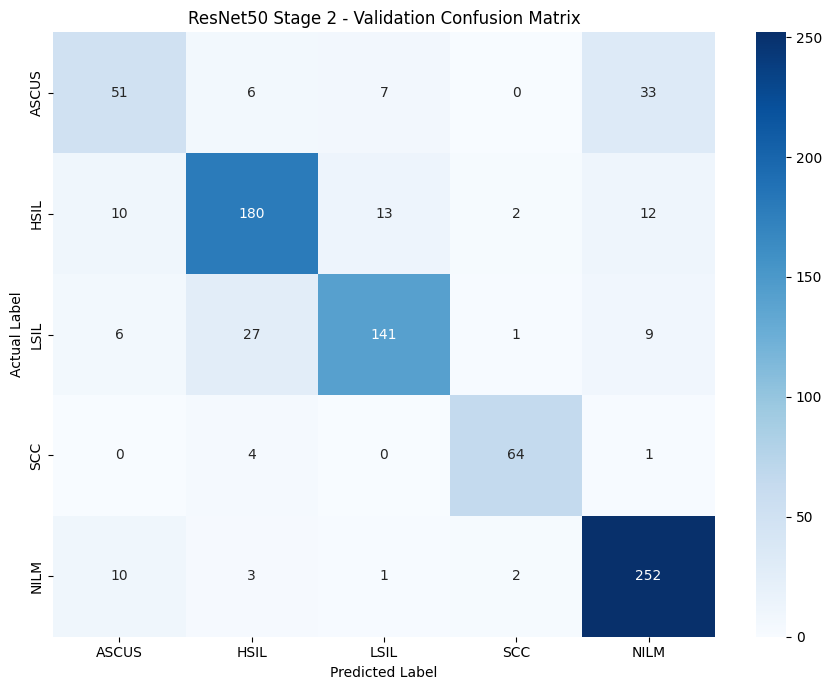

In [102]:
cm_stage2 = confusion_matrix(
    all_labels_stage2,
    all_predictions_stage2
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_stage2,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("ResNet50 Stage 2 - Validation Confusion Matrix")

plt.tight_layout()
plt.show()

In [104]:
from sklearn.metrics import classification_report, confusion_matrix

all_labels_test = []
all_predictions_test = []

model.eval()

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_labels_test.extend(labels.numpy())
        all_predictions_test.extend(predictions.cpu().numpy())


print("FINAL TEST SET RESULTS")

print(classification_report(
    all_labels_test,
    all_predictions_test,
    target_names=classes,
    digits=4
))

FINAL TEST SET RESULTS
              precision    recall  f1-score   support

       ASCUS     0.4304    0.3542    0.3886        96
        HSIL     0.8142    0.8519    0.8326       216
        LSIL     0.9122    0.7297    0.8108       185
         SCC     0.9118    0.8986    0.9051        69
        NILM     0.7930    0.9257    0.8542       269

    accuracy                         0.7952       835
   macro avg     0.7723    0.7520    0.7583       835
weighted avg     0.7930    0.7952    0.7897       835



## Conclusion

This project focused on developing an end-to-end deep learning pipeline for cervical cytology image classification using five categories: ASCUS, HSIL, LSIL, SCC, and NILM.

The project involved image data preparation, preprocessing, exploratory analysis, model development, experimentation, and performance evaluation. Multiple custom CNN configurations were initially developed and evaluated. Subsequently, transfer learning was implemented using an ImageNet-pretrained ResNet50 architecture. The model was trained in two stages: initial classifier-head training followed by fine-tuning of the final convolutional block and classification head.

The final ResNet50 model achieved an accuracy of **79.52%**, a macro F1-score of **75.83%**, and a weighted F1-score of **78.97%** on the independent test set. Among the five categories, SCC achieved the highest F1-score of 90.51%, followed by NILM at 85.42% and HSIL at 83.26%. However, ASCUS classification remained challenging, with an F1-score of 38.86%, highlighting the need for further improvements in distinguishing visually similar cytological patterns.

The experiments demonstrated the effectiveness of transfer learning and selective fine-tuning compared with the custom CNN approaches evaluated in this project. Experiment tracking and model checkpoint management were incorporated to maintain reproducibility and support systematic model comparison.

Overall, the project established a complete deep learning model-development pipeline and produced a trained ResNet50 model artifact for subsequent deployment through an API-based application. While the results demonstrate the potential of deep learning for automated cervical cytology image classification, the model is intended for research and experimental purposes only. Further validation using larger, diverse, and appropriately annotated datasets, along with improvements in underperforming classes, would be necessary before considering any clinical application.


In [107]:
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report
)

# Calculate final test metrics
accuracy = accuracy_score(
    all_labels_test,
    all_predictions_test
)

macro_precision, macro_recall, macro_f1, _ = (
    precision_recall_fscore_support(
        all_labels_test,
        all_predictions_test,
        average="macro",
        zero_division=0
    )
)

weighted_precision, weighted_recall, weighted_f1, _ = (
    precision_recall_fscore_support(
        all_labels_test,
        all_predictions_test,
        average="weighted",
        zero_division=0
    )
)

# Configure existing experiment
mlflow.set_experiment("ResNet50_TransferLearning")

# Create a separate final evaluation run
with mlflow.start_run(run_name="ResNet50_Final_Test_Evaluation"):

    # Log evaluation parameters
    mlflow.log_params({
        "model": "ResNet50",
        "evaluation_stage": "Final Test Evaluation",
        "dataset": "Test Set",
        "test_samples": len(all_labels_test),
        "num_classes": len(classes),
        "best_training_stage": "Stage 2",
        "best_epoch": 5
    })

    # Log overall metrics
    mlflow.log_metrics({
        "test_accuracy": accuracy,
        "test_macro_precision": macro_precision,
        "test_macro_recall": macro_recall,
        "test_macro_f1": macro_f1,
        "test_weighted_precision": weighted_precision,
        "test_weighted_recall": weighted_recall,
        "test_weighted_f1": weighted_f1
    })

    # Log class-wise metrics
    report = classification_report(
        all_labels_test,
        all_predictions_test,
        target_names=classes,
        output_dict=True,
        zero_division=0
    )

    for class_name in classes:

        mlflow.log_metrics({
            f"{class_name}_precision": report[class_name]["precision"],
            f"{class_name}_recall": report[class_name]["recall"],
            f"{class_name}_f1": report[class_name]["f1-score"]
        })

    print("Final test evaluation logged successfully!")
    print(f"Test Accuracy: {accuracy:.4f}")
    print(f"Macro F1: {macro_f1:.4f}")
    print(f"Weighted F1: {weighted_f1:.4f}")
    print("MLflow Run ID:", mlflow.active_run().info.run_id)

Final test evaluation logged successfully!
Test Accuracy: 0.7952
Macro F1: 0.7583
Weighted F1: 0.7897
MLflow Run ID: 7247a6141f354845b9121004ac340ef4
🏃 View run ResNet50_Final_Test_Evaluation at: https://dagshub.com/zamanwajahath/cervical-cytology-classification.mlflow/#/experiments/2/runs/7247a6141f354845b9121004ac340ef4
🧪 View experiment at: https://dagshub.com/zamanwajahath/cervical-cytology-classification.mlflow/#/experiments/2


In [109]:
# Export directory in Google Drive
EXPORT_DIR = "/content/drive/MyDrive/Cervical_Cancer_Project/model_artifacts"

os.makedirs(EXPORT_DIR, exist_ok=True)

# Load best Stage 2 checkpoint
checkpoint_path = os.path.join(
    STAGE2_DIR,
    "stage2_best_model.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

# Prepare final model artifact
final_model_artifact = {
    "architecture": "ResNet50",
    "model_state_dict": checkpoint["model_state_dict"],
    "num_classes": len(classes),
    "class_names": classes,
    "image_size": IMG_SIZE,
    "normalization": {
        "mean": [0.485, 0.456, 0.406],
        "std": [0.229, 0.224, 0.225]
    },
    "best_epoch": checkpoint["epoch"],
    "best_validation_loss": checkpoint["best_val_loss"]
}

# Save artifact
export_path = os.path.join(
    EXPORT_DIR,
    "resnet50_cervical_cytology_best.pth"
)

torch.save(final_model_artifact, export_path)

print("Model exported successfully!")
print("Export location:", export_path)
print("Architecture:", final_model_artifact["architecture"])
print("Classes:", final_model_artifact["class_names"])
print("Image size:", final_model_artifact["image_size"])
print("Best epoch:", final_model_artifact["best_epoch"])

Model exported successfully!
Export location: /content/drive/MyDrive/Cervical_Cancer_Project/model_artifacts/resnet50_cervical_cytology_best.pth
Architecture: ResNet50
Classes: ['ASCUS', 'HSIL', 'LSIL', 'SCC', 'NILM']
Image size: 512
Best epoch: 5


In [110]:
# Reload exported artifact
exported_model = torch.load(
    export_path,
    map_location="cpu",
    weights_only=False
)

print("Artifact verification successful!")
print("Architecture:", exported_model["architecture"])
print("Number of classes:", exported_model["num_classes"])
print("Class mapping:", exported_model["class_names"])
print("Input resolution:", exported_model["image_size"])
print(
    "State dictionary entries:",
    len(exported_model["model_state_dict"])
)
print(
    "File size:",
    round(os.path.getsize(export_path) / (1024 ** 2), 2),
    "MB"
)

Artifact verification successful!
Architecture: ResNet50
Number of classes: 5
Class mapping: ['ASCUS', 'HSIL', 'LSIL', 'SCC', 'NILM']
Input resolution: 512
State dictionary entries: 320
File size: 90.02 MB
